# Regresión logística — issue #18
Autora: BesteOzaydin. Baseline para Económico, Medio y Premium.

Se reutilizan las 23 variables, el split y el contrato común: F1 macro, cinco folds estratificados con semilla 42 y gap = media F1 train − media F1 validación < 0.05 absoluto. Optuna: presupuesto local de 20 trials, pendiente de un presupuesto común.

La selección y todos los diagnósticos de este notebook usan exclusivamente train. El test reservado no se inspecciona ni se evalúa aquí: su evaluación corresponde al champion seleccionado en #22. Los bins provisionales globales del split y los umbrales definitivos fijados en train siguen el contrato compartido.

**Límites:** los hiperparámetros se seleccionan con los mismos folds usados para generar las predicciones OOF; no es nested CV ni una evaluación final independiente. Además, versiones anteriores de esta baseline ya mostraron resultados del mismo test. Retirar esos resultados no deshace esa exposición: el equipo debe tenerlo en cuenta antes de presentar una evaluación final independiente. El split aleatorio no garantiza generalización a nuevos anfitriones o fechas.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, subprocess, time, warnings, shutil, os
from importlib.metadata import version
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import optuna
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from src.preprocessing import load_train_test, build_preprocessor, TARGET_LABELS, RAW_DATA_PATH
SEED, N_TRIALS = 42, 20
LABELS = list(TARGET_LABELS)
# El cargador conserva el split común; se descartan ambos objetos de test.
X_train, _, y_train, _, thresholds = load_train_test(return_thresholds=True)
assert 'price' not in X_train
assert X_train.index.equals(y_train.index)
assert X_train.shape[1] == 23
print(sys.executable, platform.python_version())
print('Train:', X_train.shape, 'Umbrales de train:', thresholds)
display(y_train.value_counts().reindex(LABELS).rename('train_count').to_frame())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Un fallo de convergencia invalida la ejecución: no se oculta.
warnings.filterwarnings('error', category=ConvergenceWarning)
def pipeline(model):
    return Pipeline([('prep', build_preprocessor()), ('model', model)])
def evaluate_cv(estimator):
    return cross_validate(estimator, X_train, y_train, cv=cv, scoring='f1_macro',
                          return_train_score=True, error_score='raise', n_jobs=1)
def summarize(scores):
    train, val = float(np.mean(scores['train_score'])), float(np.mean(scores['test_score']))
    return dict(cv_train_f1_macro=train, cv_validation_f1_macro=val,
                cv_validation_std=float(np.std(scores['test_score'])), gap=train-val,
                gap_under_005=bool(train-val < 0.05), cv_fit_seconds=float(np.sum(scores['fit_time'])))


/Users/besteozaydin/Desktop/AI_Course_Docs/P5-Cón-G6/bcn-price-classifier/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/besteozaydin/Desktop/AI_Course_Docs/P5-Cón-G6/bcn-price-classifier/.venv/bin/python 3.12.5
Train: (10088, 23) Umbrales de train: {'lower': 122.0, 'upper': 249.72333333333327}


,train_count
price_segment,
Económico,3366
Medio,3359
Premium,3363


## Referencia Dummy y regresión sin ajustar hiperparámetros
Ambas usan el mismo Pipeline y los mismos folds. Dummy usa `most_frequent`.

In [2]:
dummy = pipeline(DummyClassifier(strategy='most_frequent', random_state=SEED))
dummy_scores = evaluate_cv(dummy)
default_scores = evaluate_cv(pipeline(LogisticRegression(solver='lbfgs', max_iter=5000, random_state=SEED)))
display(pd.DataFrame([summarize(dummy_scores), summarize(default_scores)], index=['Dummy', 'LogReg default']))


,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds
Dummy,0.166791,0.166791,0.000068,8.618269e-09,True,0.236735
LogReg default,0.739780,0.728515,0.006118,1.126476e-02,True,0.894578


## Optuna solo en train
Espacio: C log-uniforme [0.001, 100]; class_weight en {None, balanced}. Solver lbfgs, regularización L2 por defecto, max_iter=5000. TPE semilla 42, 20 trials secuenciales sin pruning. Se maximiza la media de F1 macro de validación; el gap se informa, sin consultar test para corregirlo.


In [3]:
def objective(trial):
    params = {'C': trial.suggest_float('C', 1e-3, 100.0, log=True),
              'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    scores = evaluate_cv(pipeline(LogisticRegression(**params, solver='lbfgs', max_iter=5000, random_state=SEED)))
    trial.set_user_attr('cv_summary', summarize(scores))
    trial.set_user_attr('fold_train', scores['train_score'].tolist())
    trial.set_user_attr('fold_validation', scores['test_score'].tolist())
    return float(np.mean(scores['test_score']))
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
started = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
search_seconds = time.perf_counter() - started
best_summary = study.best_trial.user_attrs['cv_summary']
print('Mejor configuración:', study.best_params, 'Tiempo búsqueda:', search_seconds)
display(pd.DataFrame([best_summary]))
display(pd.DataFrame({'train_f1_macro': study.best_trial.user_attrs['fold_train'],
                      'validation_f1_macro': study.best_trial.user_attrs['fold_validation']}))
print('Requisito gap < 0.05:', best_summary['gap_under_005'])


Mejor configuración: {'C': 0.5971896122019431, 'class_weight': None} Tiempo búsqueda: 20.194710416020826


,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds
0,0.739585,0.729123,0.006091,0.010462,True,0.668796


,train_f1_macro,validation_f1_macro
0,0.738541,0.719759
1,0.740103,0.730422
2,0.740142,0.738042
3,0.740124,0.731545
4,0.739017,0.725849


Requisito gap < 0.05: True


## Diagnóstico out-of-fold sobre train
Se congelan los hiperparámetros elegidos por CV. Para Dummy y regresión logística, `cross_val_predict` recibe el Pipeline completo y los mismos cinco folds: cada fila de train se predice una vez con un Pipeline que no se ha ajustado con esa fila. El preprocesamiento se aprende dentro de cada fold.

Las métricas agregadas OOF y la media de F1 por fold son cantidades distintas: F1 es no lineal. Para seleccionar y comparar modelos se usa la media de F1 macro de validación; OOF sirve para los informes por clase y los diagnósticos de errores. Con la selección de hiperparámetros en los mismos folds, estos diagnósticos pueden ser optimistas.

Matrices: filas = clase real según precio/umbrales; columnas = clase predicha. Todas las filas pertenecen a train, no al test reservado.


DummyClassifier — train OOF


,precision,recall,f1-score,support
Económico,0.333664,1.000000,0.500372,3366.000000
Medio,0.000000,0.000000,0.000000,3359.000000
Premium,0.000000,0.000000,0.000000,3363.000000
accuracy,0.333664,0.333664,0.333664,0.333664
macro avg,0.111221,0.333333,0.166791,10088.000000
weighted avg,0.111332,0.333664,0.166956,10088.000000


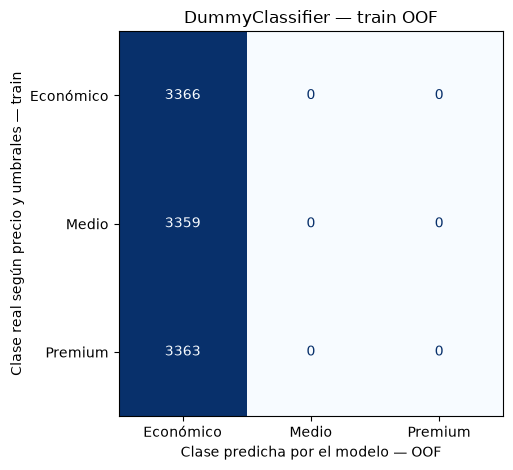

LogisticRegression — train OOF


,precision,recall,f1-score,support
Económico,0.854466,0.866904,0.860640,3366.000000
Medio,0.613202,0.611194,0.612196,3359.000000
Premium,0.718797,0.710675,0.714713,3363.000000
accuracy,0.729679,0.729679,0.729679,0.729679
macro avg,0.728821,0.729591,0.729183,10088.000000
weighted avg,0.728905,0.729679,0.729269,10088.000000


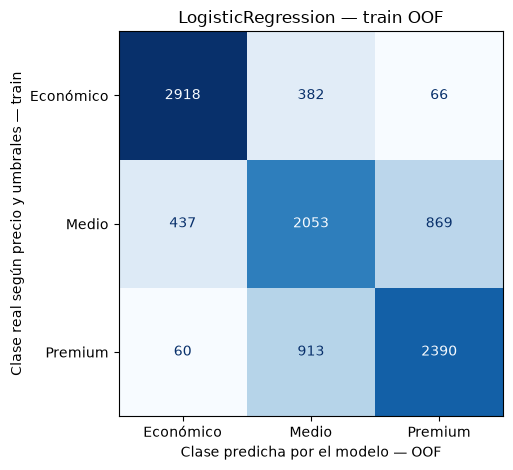

,model,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds,evaluation_set,oof_accuracy,oof_f1_macro,oof_extreme_error_rate,oof_seconds,search_seconds,params,cv,snapshot
0,DummyClassifier,0.166791,0.166791,0.000068,8.618269e-09,True,0.236735,train_oof,0.333664,0.166791,0.333366,0.296802,0.00000,"{""strategy"": ""most_frequent""}","StratifiedKFold(5, shuffle=True, random_state=42)",2026-09-17
1,LogisticRegression,0.739585,0.729123,0.006091,1.046206e-02,True,0.668796,train_oof,0.729679,0.729183,0.012490,0.650682,20.19471,"{""C"": 0.5971896122019431, ""class_weight"": null}","StratifiedKFold(5, shuffle=True, random_state=42)",2026-09-17


In [4]:
selected_model = pipeline(LogisticRegression(**study.best_params, solver='lbfgs', max_iter=5000, random_state=SEED))
rows, reports, matrices = [], {}, {}
for name, model, cv_summary in [('DummyClassifier', dummy, summarize(dummy_scores)),
                                  ('LogisticRegression', selected_model, best_summary)]:
    started = time.perf_counter()
    prediction = cross_val_predict(model, X_train, y_train, cv=cv, method='predict', n_jobs=1)
    oof_seconds = time.perf_counter() - started
    assert len(prediction) == len(y_train)
    matrix = confusion_matrix(y_train, prediction, labels=LABELS)
    reports[name] = classification_report(y_train, prediction, labels=LABELS, output_dict=True, zero_division=0)
    matrices[name] = matrix.tolist()
    rows.append(dict(model=name, **cv_summary, evaluation_set='train_oof',
                     oof_accuracy=accuracy_score(y_train, prediction),
                     oof_f1_macro=f1_score(y_train, prediction, average='macro'),
                     oof_extreme_error_rate=float((matrix[0,2]+matrix[2,0])/len(y_train)),
                     oof_seconds=oof_seconds,
                     search_seconds=search_seconds if name == 'LogisticRegression' else 0,
                     params=json.dumps(study.best_params if name == 'LogisticRegression' else {'strategy':'most_frequent'}),
                     cv='StratifiedKFold(5, shuffle=True, random_state=42)', snapshot='2026-09-17'))
    print(name, '— train OOF')
    display(pd.DataFrame(reports[name]).T)
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap='Blues', colorbar=False)
    plt.xlabel('Clase predicha por el modelo — OOF')
    plt.ylabel('Clase real según precio y umbrales — train')
    plt.title(name + ' — train OOF')
    plt.tight_layout()
    plt.show()
comparison = pd.DataFrame(rows)
display(comparison)


## Registro reproducible y tabla común
Solo se guardan métricas agregadas de validación y train OOF, sin datos ni predicciones individuales. No se generan métricas del test reservado ni se declara un champion. El notebook de comparación lee esta tabla sin volver a entrenar.


In [5]:
OUT = ROOT / 'docs' / 'results'
OUT.mkdir(parents=True, exist_ok=True)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in [ROOT / 'src/preprocessing.py', ROOT / 'src/cleaning.py']}
notebook_source = json.loads((ROOT / 'notebooks/04_model_logreg.ipynb').read_text())
source_hashes['notebook_code'] = hashlib.sha256('\n'.join(''.join(c['source']) for c in notebook_source['cells'] if c['cell_type'] == 'code').encode()).hexdigest()
provenance = dict(source_hashes=source_hashes, code_state='Base commit plus notebook changes in this delivery', code_commit=subprocess.check_output([shutil.which('git', path='/opt/homebrew/bin' + os.pathsep + os.environ.get('PATH', '')) or 'git','rev-parse','HEAD'], cwd=ROOT, text=True).strip(),
                  raw_sha256=hashlib.sha256(RAW_DATA_PATH.read_bytes()).hexdigest(),
                  thresholds=thresholds, n_train=len(X_train), n_features=X_train.shape[1],
                  evaluation_set="train_oof", nested_cv=False, historical_test_exposure=True,
                  python=platform.python_version(), seed=SEED, trials=N_TRIALS,
                  versions={p:version(p) for p in ['pandas','numpy','scikit-learn','optuna','matplotlib']},
                  protocol_status='23 variables; CV y diagnosticos OOF solo en train; test reservado al champion en #22; presupuesto local 20 trials',
                  source_notebook='notebooks/04_model_logreg.ipynb')
comparison['code_commit'] = provenance['code_commit']
comparison['raw_sha256'] = provenance['raw_sha256']
comparison.to_csv(OUT / 'logreg_comparison.csv', index=False)
(OUT / 'logreg_details.json').write_text(json.dumps(dict(provenance=provenance, reports=reports,
     confusion_matrices=matrices, best_params=study.best_params,
     folds=study.best_trial.user_attrs), ensure_ascii=False, indent=2) + '\n')
study.trials_dataframe().to_csv(OUT / 'logreg_trials.csv', index=False)
print('Resultados agregados guardados: docs/results/')


Resultados agregados guardados: docs/results/
